# -*- coding: utf-8 -*-
"""
08_05 — Brick 5: Central Story Positions  (v2 — improved)

What changed vs v1
──────────────────
1. CONFIG block at the top: change one dict instead of hunting constants.
2. Centrality logic: normalised weighted degree (0-1 range) stored alongside
   raw score; percentile computed with method="min" so ties don't inflate rank.
3. get_neighbors() vectorised — no per-row Python loop.
4. find_node_by_title() uses fuzz-ratio fallback (no extra dependency needed).
5. Figure helpers extracted so each Figure section is ~10 lines.
6. Figure 4 table is drawn with a proper grid (no manual x-offset tuning).
7. Figure 7 uses a shared y-axis scale per row so communities are comparable.
8. All file-not-found situations produce a graceful warning, not a crash.
9. Duplicate-community guard: one top film per community for profile sheets.
10. Final output manifest is printed as a tidy table.
"""

In [1]:

import os, re, math, textwrap, warnings
from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch
import matplotlib.patheffects as pe

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 220)
pd.set_option("display.max_colwidth", 240)




In [6]:
################################################################################
# 1. CONFIG  ← edit here only
################################################################################
CFG = {
    # Paths
    "project_dir":   "/content/drive/MyDrive/thesis_movie_project",
    "brick_out_dir": "outputs/thesis_bricks/05_central_story_positions",

    # Column name fallback lists (first match wins)
    "node_id_candidates":  ["tmdb_id", "id", "node_id", "movie_id", "imdb_id"],
    "title_candidates":    ["title", "film_title", "name"],
    "year_candidates":     ["release_year", "year"],
    "label_candidates":    ["suggested_label_manual", "narrative_label", "label"],
    "note_candidates":     ["interpretation_note_manual", "interpretation", "note"],
    "edge_src_candidates": ["source", "source_id", "src", "u", "node1", "from"],
    "edge_tgt_candidates": ["target", "target_id", "dst", "v", "node2", "to"],
    "weight_candidates":   ["weight", "similarity", "cosine", "score"],

    # Analysis parameters
    "top_communities":          8,    # small-multiples figure
    "profile_communities":      6,    # profile-sheet figures
    "neighborhood_films":       8,    # local ego-network
    "centrality_high_pct":     0.90,  # "top 10%" threshold
    "hist_bins":               40,
    "savefig_dpi":            320,
}



In [4]:
COL = {
    "ink":          "#222222",
    "muted":        "#62666D",
    "grid":         "#E4E7EB",
    "panel":        "#F7F8FA",
    "blue":         "#2F6FB3",
    "orange":       "#D06C45",
    "green":        "#2F8F5B",
    "purple":       "#7A5BC2",
    "red":          "#C94C4C",
    "yellow":       "#D9A21B",
    "light_blue":   "#E8F1FB",
    "light_orange": "#FBEADF",
    "light_green":  "#E6F4EC",
    "light_purple": "#EFEAFB",
    "light_gray":   "#F2F4F7",
    "white":        "#FFFFFF",
}

COMM_COLORS = [
    "#4E79A7","#F28E2B","#59A14F","#E15759","#76B7B2","#9C755F",
    "#EDC948","#B07AA1","#FF9DA7","#BAB0AC","#2F6FB3","#D06C45",
    "#2F8F5B","#7A5BC2","#C94C4C","#D9A21B","#5C6BC0","#26A69A",
    "#AB47BC","#8D6E63","#78909C","#EC407A","#43A047","#FB8C00",
    "#6D4C41","#00ACC1",
]

plt.rcParams.update({
    "figure.facecolor":   "white",
    "axes.facecolor":     "white",
    "axes.edgecolor":     COL["ink"],
    "axes.labelcolor":    COL["ink"],
    "xtick.color":        COL["ink"],
    "ytick.color":        COL["ink"],
    "text.color":         COL["ink"],
    "font.family":        "DejaVu Sans",
    "font.size":          12,
    "axes.titlesize":     18,
    "axes.titleweight":   "bold",
    "axes.labelsize":     13,
    "xtick.labelsize":    11,
    "ytick.labelsize":    11,
    "legend.fontsize":    11,
    "savefig.dpi":        CFG["savefig_dpi"],
    "figure.dpi":         130,
})




═══════════════════════════════════════════════════════════════════════════════
3. GENERIC UTILITIES
═══════════════════════════════════════════════════════════════════════════════


In [9]:
def community_color(cid):
    try:
        return COMM_COLORS[int(cid) % len(COMM_COLORS)]
    except Exception:
        return COL["blue"]

def wrap_text(s, width=42):
    if pd.isna(s):
        return ""
    return "\n".join(textwrap.wrap(str(s), width=width))

def shorten(s, width=90):
    if pd.isna(s):
        return ""
    return textwrap.shorten(str(s).replace("\n", " "), width=width, placeholder="…")

def clean_title(x):
    if pd.isna(x):
        return ""
    return str(x).replace("\n", " ").strip()

def fmt_int(x):
    try:
        return f"{int(round(float(x))):,}"
    except Exception:
        return "—"

def fmt_float(x, d=3):
    try:
        return f"{float(x):.{d}f}"
    except Exception:
        return "—"

def first_col(df, candidates):
    """Return the first column name from *candidates* that exists in df."""
    for c in candidates:
        if c in df.columns:
            return c
    return None

def safe_read(path, label=""):
    path = Path(path)
    if path.exists():
        return pd.read_csv(path)
    print(f"⚠  Missing{' (' + label + ')' if label else ''}: {path}")
    return None


Return the first column name from *candidates* that exists in df.


═══════════════════════════════════════════════════════════════════════════════
4. FIGURE / IO HELPERS
═══════════════════════════════════════════════════════════════════════════════


In [19]:
import os

def save_fig(fig, name, dpi=None):
    dpi = dpi or CFG["savefig_dpi"]
    for ext in (".png", ".svg"):
        p = FIG_DIR / name.replace(".png", ext)
        fig.savefig(p, dpi=dpi, bbox_inches="tight", facecolor="white")
        print(f"  ✓ {p.name}")

def save_table(df, name):
    p = TABLE_DIR / name
    os.makedirs(p.parent, exist_ok=True) # Ensure directory exists using os.makedirs
    df.to_csv(p, index=False, encoding="utf-8")
    print(f"  ✓ {p.name}")
    return p

def write_text(txt, name):
    p = TEXT_DIR / name
    p.write_text(txt, encoding="utf-8")
    print(f"  ✓ {p.name}")
    return p

def title_block(fig, title, subtitle=None, x=0.05, y=0.965):
    fig.text(x, y,        title,    ha="left", va="top", fontsize=22,   fontweight="bold", color=COL["ink"])
    if subtitle:
        fig.text(x, y-0.055, subtitle, ha="left", va="top", fontsize=12.5, color=COL["muted"])

═══════════════════════════════════════════════════════════════════════════════
5. PROJECT PATHS
═══════════════════════════════════════════════════════════════════════════════


In [20]:

try:
    from google.colab import drive
    if not Path("/content/drive/MyDrive").exists():
        drive.mount("/content/drive")
    else:
        print("Google Drive already mounted.")
except Exception as e:
    print("Drive mount skipped:", e)

PROJECT_DIR           = Path(CFG["project_dir"]).resolve()
PROCESSED_CORE_DIR    = PROJECT_DIR / "processed" / "core"
PROCESSED_NETWORK_DIR = PROJECT_DIR / "processed" / "network"
OUTPUT_TABLES_DIR     = PROJECT_DIR / "outputs"   / "tables"

FINAL_DIR = PROJECT_DIR / CFG["brick_out_dir"]
FIG_DIR   = FINAL_DIR / "figures"
TABLE_DIR = FINAL_DIR / "tables"
TEXT_DIR  = FINAL_DIR / "text"

for d in [FINAL_DIR, FIG_DIR, TABLE_DIR, TEXT_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print("PROJECT_DIR:", PROJECT_DIR)
print("FINAL_DIR:  ", FINAL_DIR)




Google Drive already mounted.
PROJECT_DIR: /content/drive/MyDrive/thesis_movie_project
FINAL_DIR:   /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/05_central_story_positions


═══════════════════════════════════════════════════════════════════════════════
6. LOAD FILES
═══════════════════════════════════════════════════════════════════════════════


In [21]:

FILES = {
    "nodes":                      PROCESSED_NETWORK_DIR / "semantic_network_nodes_lcc.csv",
    "edges":                      PROCESSED_NETWORK_DIR / "semantic_network_edges_mutual_knn.csv",
    "community_labels":           OUTPUT_TABLES_DIR / "community_manual_labeling_template_labeled.csv",
    "top_visible_central":        OUTPUT_TABLES_DIR / "top_visible_central_films_per_community.csv",
    "top_weighted_degree_visible":OUTPUT_TABLES_DIR / "top_weighted_degree_visible_franchise_capped.csv",
    "top_weighted_degree_franchise":OUTPUT_TABLES_DIR / "top_weighted_degree_franchise_capped.csv",
    "top_weighted_degree_raw":    OUTPUT_TABLES_DIR / "top_weighted_degree_raw.csv",
}

print("\nFile availability:")
for k, p in FILES.items():
    print(f"  {'✓' if p.exists() else '✗'}  {k:40s}  {p.name}")

nodes             = safe_read(FILES["nodes"],             "nodes")
edges             = safe_read(FILES["edges"],             "edges")
community_labels  = safe_read(FILES["community_labels"],  "community_labels")
top_visible_central        = safe_read(FILES["top_visible_central"])
top_weighted_degree_visible= safe_read(FILES["top_weighted_degree_visible"])
top_weighted_degree_franchise= safe_read(FILES["top_weighted_degree_franchise"])
top_weighted_degree_raw    = safe_read(FILES["top_weighted_degree_raw"])

if nodes is None or edges is None:
    raise FileNotFoundError(
        "Brick 5 requires semantic_network_nodes_lcc.csv and "
        "semantic_network_edges_mutual_knn.csv."
    )

# ── column detection ──────────────────────────────────────────────────────────
source_col  = first_col(edges, CFG["edge_src_candidates"]) or edges.columns[0]
target_col  = first_col(edges, CFG["edge_tgt_candidates"]) or edges.columns[1]
weight_col  = first_col(edges, CFG["weight_candidates"])

node_id_col = first_col(nodes, CFG["node_id_candidates"]) or nodes.columns[0]
title_col   = first_col(nodes, CFG["title_candidates"])   or nodes.columns[0]
year_col    = first_col(nodes, CFG["year_candidates"])

# ── attach community labels ───────────────────────────────────────────────────
label_col = note_col = None
if community_labels is not None:
    label_col = first_col(community_labels, CFG["label_candidates"])
    note_col  = first_col(community_labels, CFG["note_candidates"])
    if label_col and "community_id" in community_labels.columns:
        label_lookup = (
            community_labels[["community_id", label_col]]
            .drop_duplicates()
            .rename(columns={label_col: "narrative_label"})
        )
        if "narrative_label" not in nodes.columns and "community_id" in nodes.columns:
            nodes = nodes.merge(label_lookup, on="community_id", how="left")
        for name in ["top_visible_central","top_weighted_degree_visible",
                     "top_weighted_degree_franchise","top_weighted_degree_raw"]:
            df = globals()[name]
            if df is not None and "community_id" in df.columns and "narrative_label" not in df.columns:
                globals()[name] = df.merge(label_lookup, on="community_id", how="left")

print(f"\nnodes:      {nodes.shape}")
print(f"edges:      {edges.shape}")
print(f"source_col: {source_col}  target_col: {target_col}  weight_col: {weight_col}")
print(f"node_id:    {node_id_col}  title: {title_col}  year: {year_col}")





File availability:
  ✓  nodes                                     semantic_network_nodes_lcc.csv
  ✓  edges                                     semantic_network_edges_mutual_knn.csv
  ✓  community_labels                          community_manual_labeling_template_labeled.csv
  ✓  top_visible_central                       top_visible_central_films_per_community.csv
  ✓  top_weighted_degree_visible               top_weighted_degree_visible_franchise_capped.csv
  ✓  top_weighted_degree_franchise             top_weighted_degree_franchise_capped.csv
  ✓  top_weighted_degree_raw                   top_weighted_degree_raw.csv

nodes:      (19202, 31)
edges:      (86685, 9)
source_col: source_node_id  target_col: target_node_id  weight_col: None
node_id:    tmdb_id  title: title  year: release_year


═══════════════════════════════════════════════════════════════════════════════
7. BUILD CENTRALITY  (vectorised, normalised)
═══════════════════════════════════════════════════════════════════════════════


In [22]:

# Standardise edge table once
edge_tmp = edges[[source_col, target_col] + ([weight_col] if weight_col else [])].copy()
edge_tmp.columns = ["source_id", "target_id"] + (["edge_weight"] if weight_col else [])
if "edge_weight" not in edge_tmp.columns:
    edge_tmp["edge_weight"] = 1.0

# Weighted degree (vectorised)
long = pd.concat([
    edge_tmp[["source_id", "edge_weight"]].rename(columns={"source_id": "node_id"}),
    edge_tmp[["target_id", "edge_weight"]].rename(columns={"target_id": "node_id"}),
])
agg = long.groupby("node_id")["edge_weight"].agg(
    degree_from_edges="count",
    weighted_degree_from_edges="sum"
).reset_index().rename(columns={"node_id": node_id_col})

central_nodes = nodes.merge(agg, on=node_id_col, how="left")
central_nodes[["degree_from_edges","weighted_degree_from_edges"]] = (
    central_nodes[["degree_from_edges","weighted_degree_from_edges"]].fillna(0)
)

# Choose primary centrality score
if "weighted_degree" in central_nodes.columns:
    central_nodes["centrality_score"] = central_nodes["weighted_degree"]
else:
    central_nodes["centrality_score"] = central_nodes["weighted_degree_from_edges"]

# Normalised score (0-1), avoids scale dependence across comparisons
s = central_nodes["centrality_score"]
central_nodes["centrality_score_norm"] = (s - s.min()) / (s.max() - s.min() + 1e-12)

# Percentile with method="min" so ties don't inflate rank
central_nodes["centrality_percentile"] = central_nodes["centrality_score"].rank(
    pct=True, method="min"
)

# Node lookup (fast O(1) access)
node_lookup = central_nodes.set_index(node_id_col, drop=False)

save_table(central_nodes, "00_centrality_node_diagnostics.csv")
print(f"\nCentrality built for {len(central_nodes):,} nodes.")
print(central_nodes[["centrality_score","centrality_score_norm","centrality_percentile"]].describe().round(3))




  ✓ 00_centrality_node_diagnostics.csv

Centrality built for 19,202 nodes.
       centrality_score  centrality_score_norm  centrality_percentile
count         19202.000              19202.000              19202.000
mean              4.700                  0.309                  0.500
std               2.772                  0.196                  0.289
min               0.337                  0.000                  0.000
25%               2.455                  0.150                  0.250
50%               4.295                  0.280                  0.500
75%               6.544                  0.439                  0.750
max              14.479                  1.000                  1.000


═══════════════════════════════════════════════════════════════════════════════
8. LOOKUP HELPERS
═══════════════════════════════════════════════════════════════════════════════


In [24]:
def film_info(node_id, field, default="—"):
    """Generic single-field lookup from the node index."""
    v = node_lookup.loc[node_id].get(field, default)
    return default if pd.isna(v) else v


Generic single-field lookup from the node index.


In [27]:
def film_title(node_id):   return clean_title(film_info(node_id, title_col, node_id))
def film_year(node_id):
    v = film_info(node_id, year_col, "—") if year_col else "—"
    try:    return int(v)
    except: return v
def film_community(node_id):
    v = film_info(node_id, "community_id", "—")
    try:    return int(v)
    except: return v
def film_label(node_id):
    return str(film_info(node_id, "narrative_label", ""))


def find_node_by_title(title):
    """Exact → contains → simple token-overlap fallback."""
    if pd.isna(title):
        return None
    t = str(title).strip().lower()
    # 1. exact
    hit = central_nodes[central_nodes[title_col].astype(str).str.strip().str.lower() == t]
    if len(hit):
        return hit.iloc[0]
    # 2. substring
    hit = central_nodes[central_nodes[title_col].astype(str).str.lower().str.contains(
        re.escape(t), na=False)]
    if len(hit):
        return hit.iloc[0]
    # 3. token overlap (no external library required)
    query_tokens = set(t.split())
    def overlap(s):
        return len(query_tokens & set(str(s).lower().split())) / max(len(query_tokens), 1)
    scores = central_nodes[title_col].apply(overlap)
    best_idx = scores.idxmax()
    if scores[best_idx] >= 0.5:
        return central_nodes.loc[best_idx]
    return None


Exact → contains → simple token-overlap fallback.


Return top-N neighbours by edge weight — fully vectorised.


In [29]:
def get_neighbors(anchor_id, top_n=8):
    """Return top-N neighbours by edge weight — fully vectorised."""
    mask = (edge_tmp["source_id"] == anchor_id) | (edge_tmp["target_id"] == anchor_id)
    sub  = edge_tmp[mask].copy()
    if sub.empty:
        return pd.DataFrame()
    sub["neighbor_id"] = np.where(
        sub["source_id"] == anchor_id, sub["target_id"], sub["source_id"]
    )
    sub = sub.nlargest(top_n, "edge_weight")

    # Vectorised attribute join
    neighbor_info = (
        central_nodes.set_index(node_id_col)
        [filter(lambda c: c in central_nodes.columns,
                [title_col, year_col or "release_year", "community_id",
                 "narrative_label", "centrality_score"])]
        .rename(columns={
            title_col:                   "neighbor_title",
            (year_col or "release_year"):"neighbor_year",
            "community_id":              "neighbor_community",
            "narrative_label":           "neighbor_label",
            "centrality_score":          "neighbor_centrality_score",
        })
    )
    result = sub.merge(
        neighbor_info, left_on="neighbor_id", right_index=True, how="left"
    )
    result.insert(0, "anchor_id", anchor_id)
    return result.reset_index(drop=True)


═══════════════════════════════════════════════════════════════════════════════
9. CENTRAL SOURCE (pick best available ranked list)
═══════════════════════════════════════════════════════════════════════════════


In [32]:

central_source = None
for df in [top_visible_central, top_weighted_degree_visible,
           top_weighted_degree_franchise, top_weighted_degree_raw]:
    if df is not None and len(df):
        central_source = df.copy()
        break

if central_source is None:
    central_source = central_nodes.sort_values("centrality_score", ascending=False).copy()

# Attach node IDs if missing (batch — avoids per-row loop)
if node_id_col not in central_source.columns:
    t_series  = central_source.get("title", central_source.iloc[:, 0]).astype(str).str.strip().str.lower()

    # Fix: Ensure the lookup `id_series` has a unique index
    title_to_id_map_df = central_nodes[[title_col, node_id_col]].copy()
    title_to_id_map_df['standardized_title'] = title_to_id_map_df[title_col].astype(str).str.strip().str.lower()
    # Drop duplicates based on the standardized title, keeping the first occurrence
    title_to_id_map_df = title_to_id_map_df.drop_duplicates(subset=['standardized_title'], keep='first')
    id_series = title_to_id_map_df.set_index('standardized_title')[node_id_col]

    central_source[node_id_col] = t_series.map(id_series)

central_source = central_source.dropna(subset=[node_id_col]).copy()

# Attach scores if missing
score_cols = [c for c in ["centrality_score","degree_from_edges",
                           "weighted_degree_from_edges","centrality_percentile"]
              if c not in central_source.columns]
if score_cols:
    central_source = central_source.merge(
        central_nodes[[node_id_col] + score_cols], on=node_id_col, how="left"
    )

save_table(central_source, "00_central_source_for_figures.csv")
display(central_source.head())


  ✓ 00_central_source_for_figures.csv


,community_id,rank_within_community,title,release_year,primary_genre,vote_count,vote_average,weighted_degree,betweenness_centrality_sampled,pagerank,n_films,top_genre,narrative_label,tmdb_id,centrality_score,degree_from_edges,weighted_degree_from_edges,centrality_percentile
0,14,1,The Kindred,2021,Horror,125.0,6.400,13.124843,0.000343,0.000090,1792,Drama,"Broad personal drama, family disruption, and domestic threat",854188,13.124843,0.0,0.0,0.999792
1,14,2,Beyond the Law,2019,Action,102.0,5.200,12.964603,0.000399,0.000090,1792,Drama,"Broad personal drama, family disruption, and domestic threat",18631,1.442803,5.0,5.0,0.112905
2,14,3,The Boogeyman,2023,Horror,1062.0,6.400,12.942888,0.000176,0.000085,1792,Drama,"Broad personal drama, family disruption, and domestic threat",532408,12.942888,0.0,0.0,0.999375
3,22,1,Amer,2009,Thriller,169.0,6.200,13.117239,0.000102,0.000094,1735,Drama,"Relationship drama, romantic comedy, and emotional-family crossover",43950,13.117239,0.0,0.0,0.999740
4,22,2,Something New,2016,Comedy,223.0,5.679,12.563270,0.000286,0.000090,1735,Drama,"Relationship drama, romantic comedy, and emotional-family crossover",15363,1.456134,16.0,16.0,0.115821


═══════════════════════════════════════════════════════════════════════════════
10. FIGURE 1 — Centrality as story typicality
═══════════════════════════════════════════════════════════════════════════════


  ✓ 01_centrality_as_story_typicality.png
  ✓ 01_centrality_as_story_typicality.svg


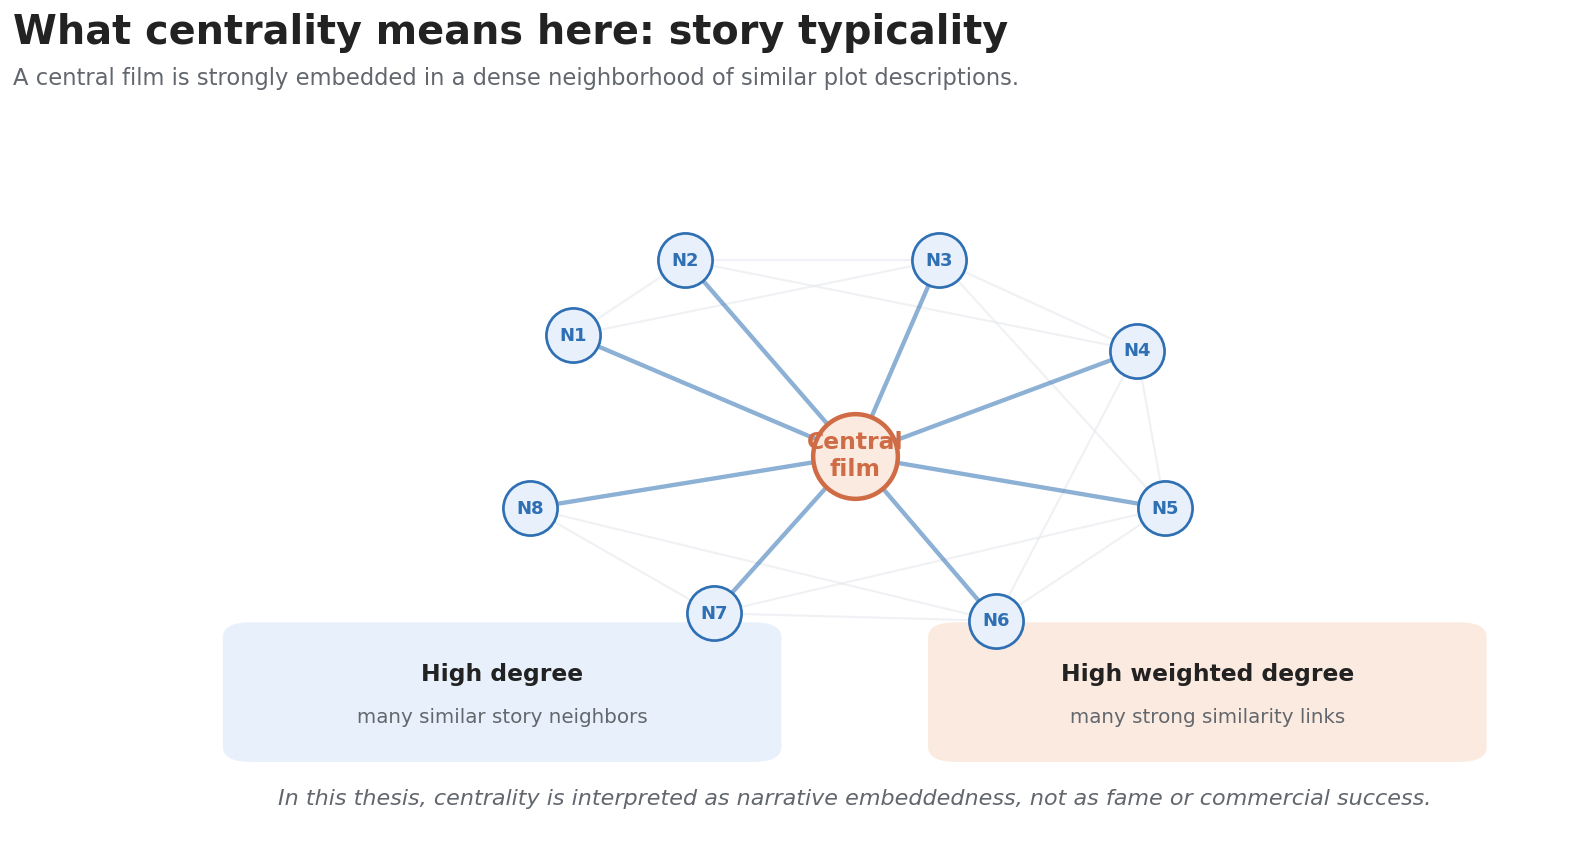

In [33]:

fig, ax = plt.subplots(figsize=(14, 7.5))
ax.axis("off"); ax.set_xlim(0,1); ax.set_ylim(0,1)
title_block(fig,
    "What centrality means here: story typicality",
    "A central film is strongly embedded in a dense neighborhood of similar plot descriptions.")

center    = (0.50, 0.52)
neighbors = [(0.30,0.68),(0.38,0.78),(0.56,0.78),(0.70,0.66),
             (0.72,0.45),(0.60,0.30),(0.40,0.31),(0.27,0.45)]

# Faint neighbour-neighbour links
for i,(x1,y1) in enumerate(neighbors):
    for j,(x2,y2) in enumerate(neighbors):
        if i < j and abs(i-j) <= 2:
            ax.plot([x1,x2],[y1,y2], color=COL["grid"], lw=1.2, alpha=0.55, zorder=1)

# Strong central links
for x,y in neighbors:
    ax.plot([center[0],x],[center[1],y], color=COL["blue"], lw=2.4, alpha=0.55, zorder=2)

for i,(x,y) in enumerate(neighbors, 1):
    ax.scatter(x, y, s=900, color=COL["light_blue"], edgecolor=COL["blue"], lw=1.5, zorder=3)
    ax.text(x, y, f"N{i}", ha="center", va="center", fontsize=10, fontweight="bold",
            color=COL["blue"], zorder=4)

ax.scatter(*center, s=2200, color=COL["light_orange"], edgecolor=COL["orange"], lw=2.5, zorder=5)
ax.text(*center, "Central\nfilm", ha="center", va="center", fontsize=13,
        fontweight="bold", color=COL["orange"], zorder=6)

for x0, label, sub, bg in [
    (0.07, "High degree",          "many similar story neighbors",  COL["light_blue"]),
    (0.57, "High weighted degree", "many strong similarity links",  COL["light_orange"]),
]:
    ax.add_patch(FancyBboxPatch((x0,0.13),0.36,0.15,
        boxstyle="round,pad=0.018,rounding_size=0.02", facecolor=bg, edgecolor="none"))
    ax.text(x0+0.18, 0.22, label, ha="center", fontsize=13, fontweight="bold")
    ax.text(x0+0.18, 0.165, sub,  ha="center", fontsize=11, color=COL["muted"])

ax.text(0.5, 0.055,
    "In this thesis, centrality is interpreted as narrative embeddedness, not as fame or commercial success.",
    ha="center", fontsize=12.3, color=COL["muted"], style="italic")

save_fig(fig, "01_centrality_as_story_typicality.png")
plt.show()




═══════════════════════════════════════════════════════════════════════════════
11. FIGURE 2 — Weighted-degree explainer
═══════════════════════════════════════════════════════════════════════════════


  ✓ 02_weighted_degree_explainer.png
  ✓ 02_weighted_degree_explainer.svg


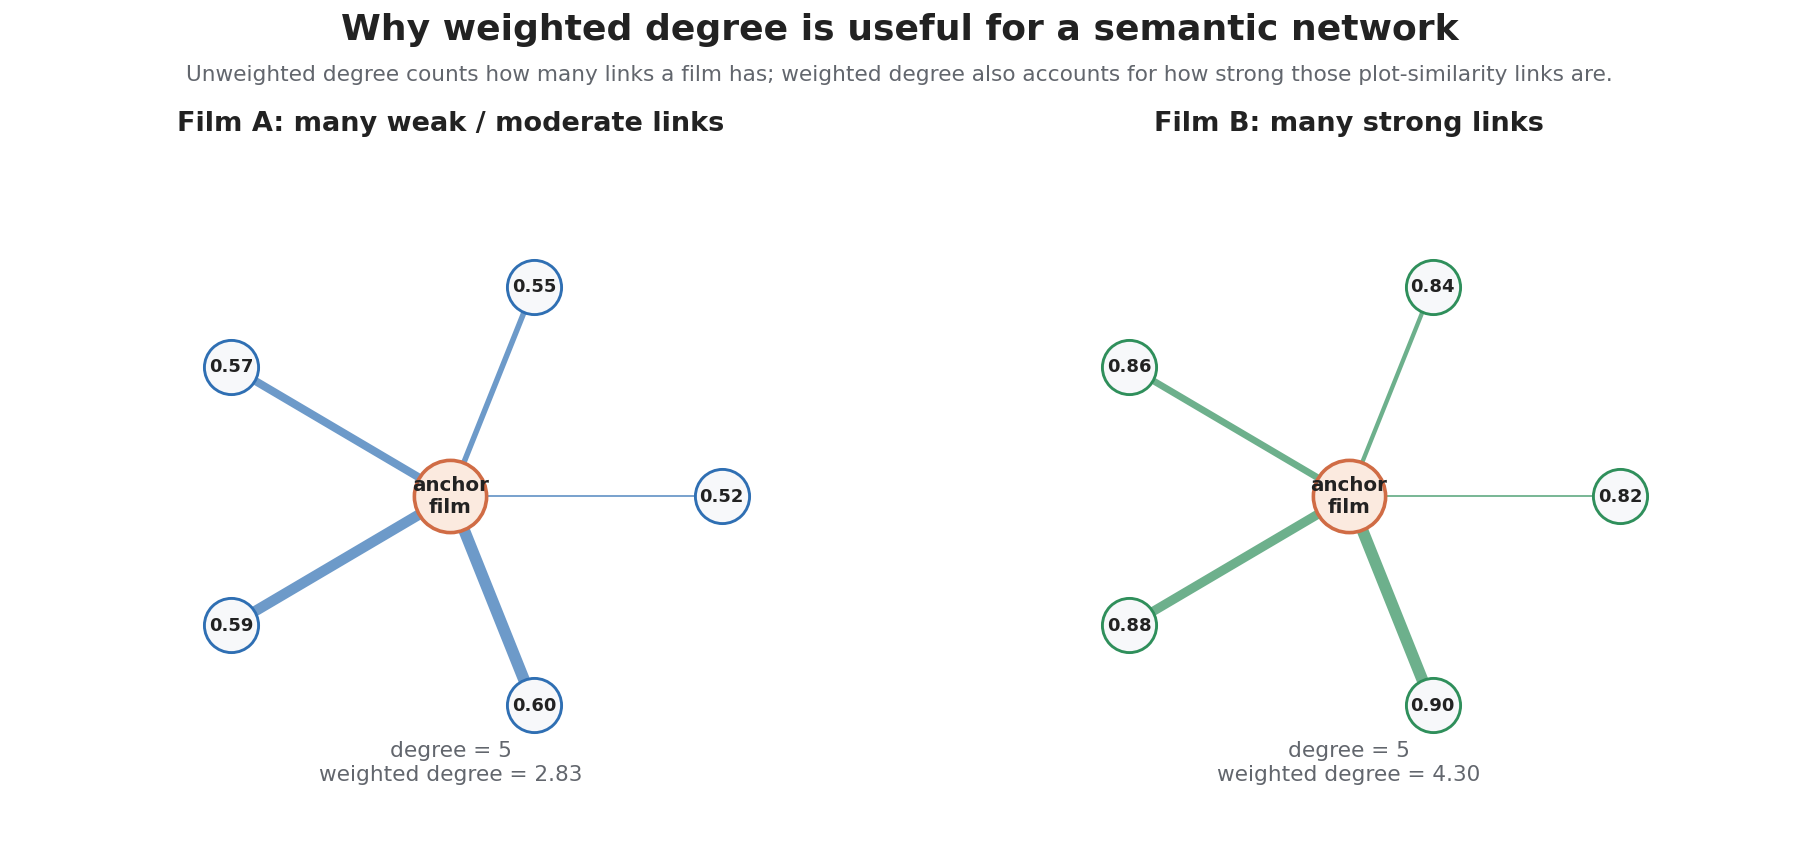

In [34]:

fig, axes = plt.subplots(1, 2, figsize=(14, 6.5))
fig.suptitle("Why weighted degree is useful for a semantic network",
             fontsize=20, fontweight="bold", y=1.02)
fig.text(0.5, 0.94,
    "Unweighted degree counts how many links a film has; "
    "weighted degree also accounts for how strong those plot-similarity links are.",
    ha="center", fontsize=12, color=COL["muted"])

toy_sets = [
    ("Film A: many weak / moderate links", [0.52,0.55,0.57,0.59,0.60], COL["blue"]),
    ("Film B: many strong links",          [0.82,0.84,0.86,0.88,0.90], COL["green"]),
]

for ax,(title,weights,color) in zip(axes, toy_sets):
    ax.axis("off"); ax.set_xlim(0,1); ax.set_ylim(0,1)
    center  = (0.50, 0.50)
    angles  = np.linspace(0, 2*np.pi, len(weights), endpoint=False)
    radius  = 0.31
    w_range = max(weights) - min(weights) + 1e-9

    ax.scatter(*center, s=1600, color=COL["light_orange"], edgecolor=COL["orange"], lw=2.0, zorder=5)
    ax.text(*center, "anchor\nfilm", ha="center", va="center", fontsize=11,
            fontweight="bold", zorder=6)

    for i,(w,angle) in enumerate(zip(weights,angles), 1):
        x = center[0] + radius*np.cos(angle)
        y = center[1] + radius*np.sin(angle)
        lw = 1.0 + 5.5*((w - min(weights)) / w_range)
        ax.plot([center[0],x],[center[1],y], color=color, lw=lw, alpha=0.70, zorder=2)
        ax.scatter(x, y, s=900, color=COL["panel"], edgecolor=color, lw=1.6, zorder=3)
        ax.text(x, y, f"{w:.2f}", ha="center", va="center", fontsize=10,
                fontweight="bold", zorder=4)

    ax.set_title(title, fontsize=15, fontweight="bold")
    ax.text(0.5, 0.10,
        f"degree = {len(weights)}\nweighted degree = {sum(weights):.2f}",
        ha="center", fontsize=12, color=COL["muted"])

plt.tight_layout()
save_fig(fig, "02_weighted_degree_explainer.png")
plt.show()




═══════════════════════════════════════════════════════════════════════════════
12. FIGURE 3 — Weighted-degree distribution
═══════════════════════════════════════════════════════════════════════════════


  ✓ 03_weighted_degree_distribution_summary.csv
  ✓ 03_weighted_degree_distribution.png
  ✓ 03_weighted_degree_distribution.svg


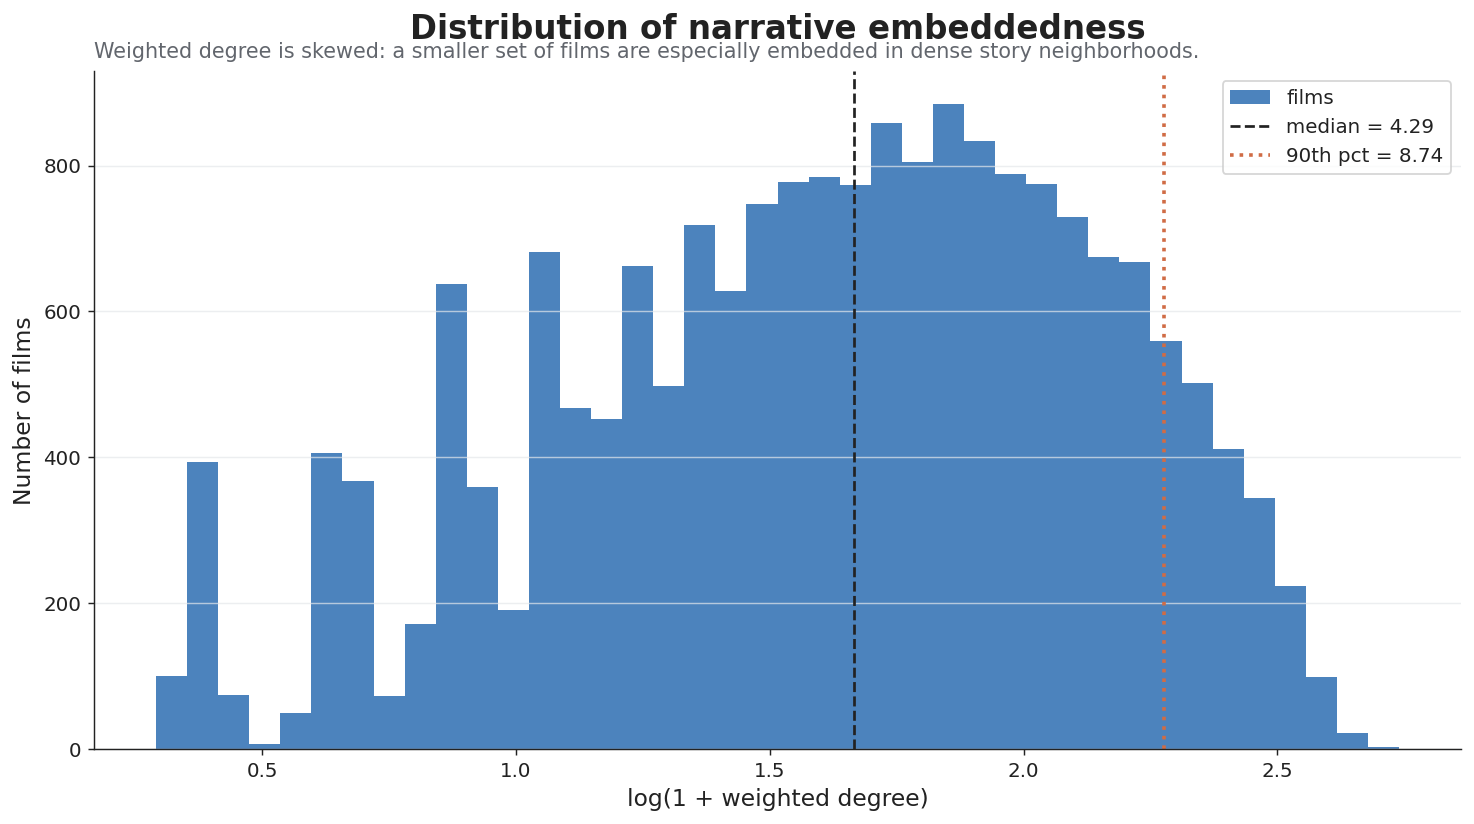

In [35]:

x       = central_nodes["centrality_score"].dropna()
x_log   = np.log1p(x)
pcts    = [0.25, 0.50, 0.75, 0.90, 0.95]
summary = pd.DataFrame({
    "metric": ["n","min","median","mean"] + [f"p{int(p*100)}" for p in pcts] + ["max"],
    "value":  [len(x), x.min(), x.median(), x.mean()] +
              [x.quantile(p) for p in pcts] + [x.max()]
})
save_table(summary, "03_weighted_degree_distribution_summary.csv")

fig, ax = plt.subplots(figsize=(11.5, 6.5))
ax.hist(x_log, bins=CFG["hist_bins"], color=COL["blue"], alpha=0.86, label="films")
ax.axvline(np.log1p(x.median()),      color=COL["ink"],    ls="--", lw=1.5,
           label=f"median = {x.median():.2f}")
ax.axvline(np.log1p(x.quantile(.90)), color=COL["orange"], ls=":",  lw=2.0,
           label=f"90th pct = {x.quantile(.90):.2f}")

ax.set_title("Distribution of narrative embeddedness", pad=18)
ax.text(0, 1.02,
    "Weighted degree is skewed: a smaller set of films are especially embedded in dense story neighborhoods.",
    transform=ax.transAxes, fontsize=11.5, color=COL["muted"])
ax.set_xlabel("log(1 + weighted degree)")
ax.set_ylabel("Number of films")
ax.spines[["top","right"]].set_visible(False)
ax.grid(axis="y", color=COL["grid"], alpha=0.7)
ax.legend()

plt.tight_layout()
save_fig(fig, "03_weighted_degree_distribution.png")
plt.show()




═══════════════════════════════════════════════════════════════════════════════
13. FIGURE 4 — Central films by community (table)
═══════════════════════════════════════════════════════════════════════════════


  ✓ 04_central_films_by_community_table.csv
  ✓ 04_central_films_by_community_table.png
  ✓ 04_central_films_by_community_table.svg


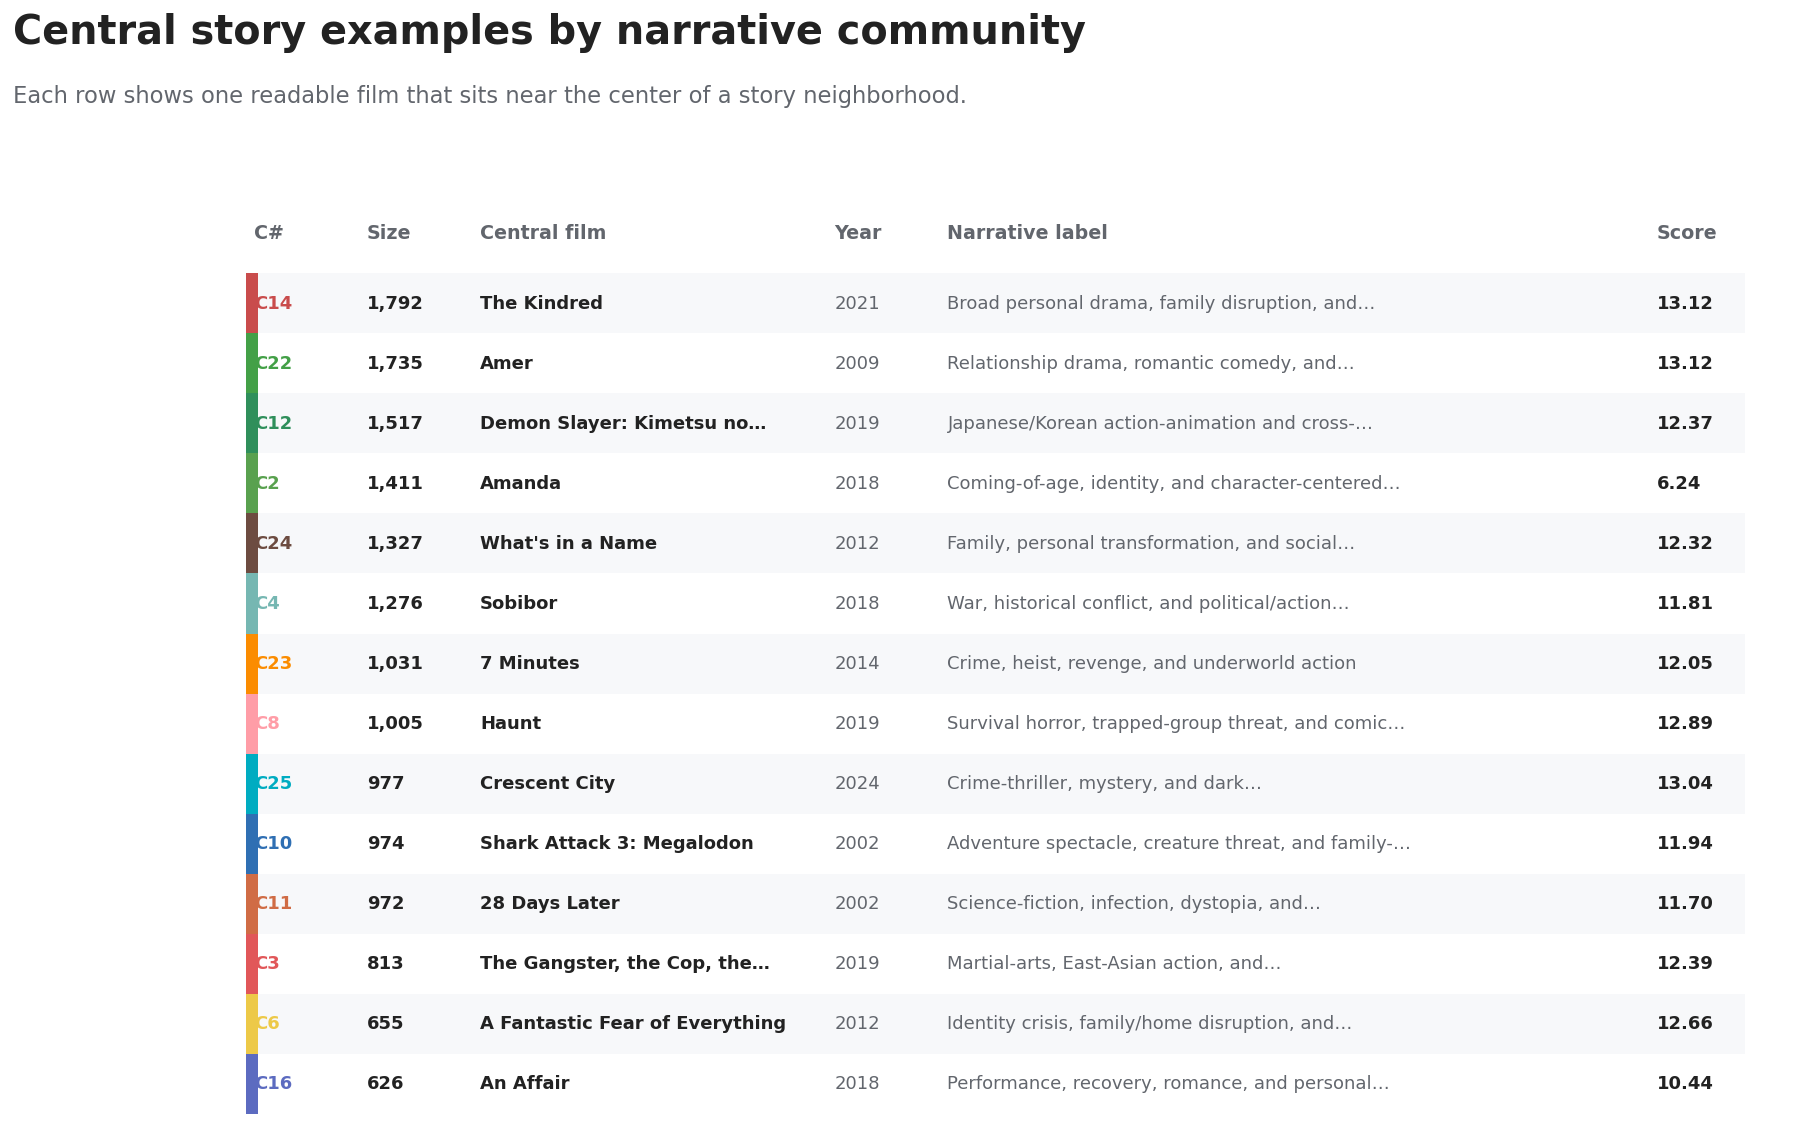

In [36]:

central = central_source.copy()

if "rank_within_community" in central.columns:
    central_one = central.sort_values("rank_within_community").groupby("community_id").head(1)
else:
    central_one = central.sort_values("centrality_score", ascending=False).groupby("community_id").head(1)

# Attach community metadata
if community_labels is not None:
    size_cols = [c for c in ["community_id","n_films", label_col]
                 if c and c in community_labels.columns]
    cmeta = community_labels[size_cols].drop_duplicates()
    central_one = central_one.merge(cmeta, on="community_id", how="left", suffixes=("","_meta"))
    if "narrative_label" not in central_one.columns and label_col in central_one.columns:
        central_one["narrative_label"] = central_one[label_col]

n_films_col = "n_films" if "n_films" in central_one.columns else None
if n_films_col:
    central_one = central_one.sort_values(n_films_col, ascending=False).head(14)
else:
    central_one = central_one.head(14)

save_table(central_one, "04_central_films_by_community_table.csv")

# ── draw ──────────────────────────────────────────────────────────────────────
HEADERS = ["C#", "Size", "Central film", "Year", "Narrative label", "Score"]
COLS_W  = [0.07, 0.07, 0.22, 0.07, 0.44, 0.08]   # fractional column widths
ROW_H   = 0.060

fig, ax = plt.subplots(figsize=(16, 10))
ax.axis("off")
title_block(fig,
    "Central story examples by narrative community",
    "Each row shows one readable film that sits near the center of a story neighborhood.",
    x=0.04, y=0.965)

# Column x-starts from widths
xs = [0.04]
for w in COLS_W[:-1]:
    xs.append(xs[-1] + w)

start_y = 0.84
for j,(h,x0) in enumerate(zip(HEADERS, xs)):
    ax.text(x0, start_y+0.045, h, transform=ax.transAxes,
            fontsize=10.5, fontweight="bold", color=COL["muted"])

for i,(_,r) in enumerate(central_one.iterrows()):
    y     = start_y - i*ROW_H
    cid   = int(r["community_id"])
    color = community_color(cid)
    bg    = COL["panel"] if i%2==0 else "white"
    # row background
    ax.add_patch(mpatches.Rectangle(
        (0.035, y-ROW_H+0.010), 0.93, ROW_H,
        transform=ax.transAxes, facecolor=bg, edgecolor="none"))
    # left colour bar
    ax.add_patch(mpatches.Rectangle(
        (0.035, y-ROW_H+0.010), 0.007, ROW_H,
        transform=ax.transAxes, facecolor=color, edgecolor="none"))

    title_val = clean_title(r.get("title", r.get(title_col, "")))
    year_val  = r.get(year_col or "release_year", "")
    try:    year_val = int(float(year_val)) if pd.notna(year_val) else ""
    except: pass

    vals = [
        f"C{cid}",
        fmt_int(r.get("n_films","")) if n_films_col else "—",
        shorten(title_val, 30),
        str(year_val),
        shorten(r.get("narrative_label",""), 50),
        fmt_float(r.get("centrality_score", np.nan), 2),
    ]
    weights = ["bold","bold","bold","normal","normal","bold"]
    colors  = [color, COL["ink"], COL["ink"], COL["muted"], COL["muted"], COL["ink"]]

    for v, x0, fw, fc in zip(vals, xs, weights, colors):
        ax.text(x0, y-0.020, v, transform=ax.transAxes,
                fontsize=10.0, fontweight=fw, color=fc, va="center")

save_fig(fig, "04_central_films_by_community_table.png")
plt.show()




═══════════════════════════════════════════════════════════════════════════════
14. FIGURE 5 — Central story profile sheets
═══════════════════════════════════════════════════════════════════════════════


  ✓ 05_central_story_profile_C14.png
  ✓ 05_central_story_profile_C14.svg


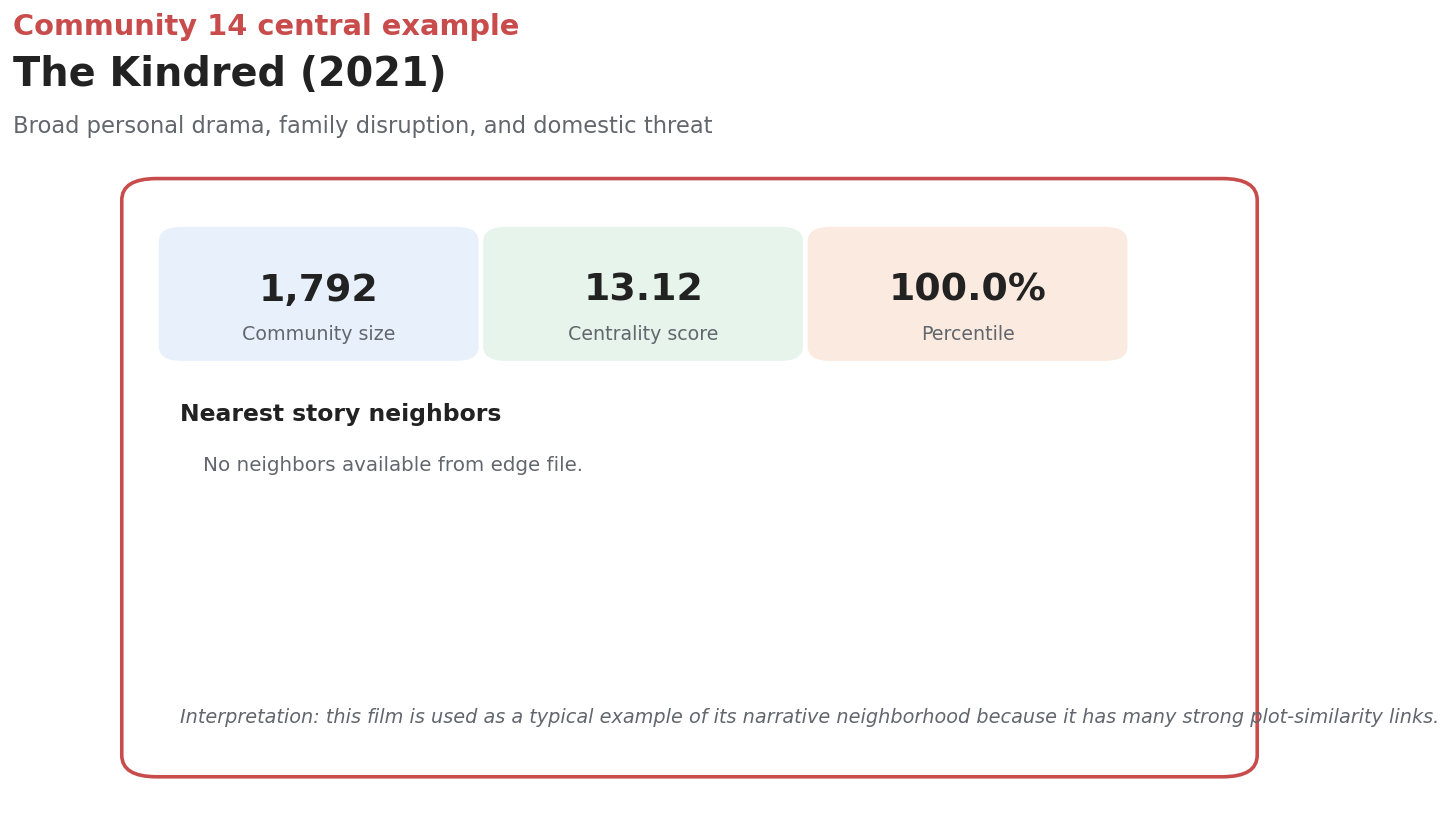

  ✓ 05_central_story_profile_C22.png
  ✓ 05_central_story_profile_C22.svg


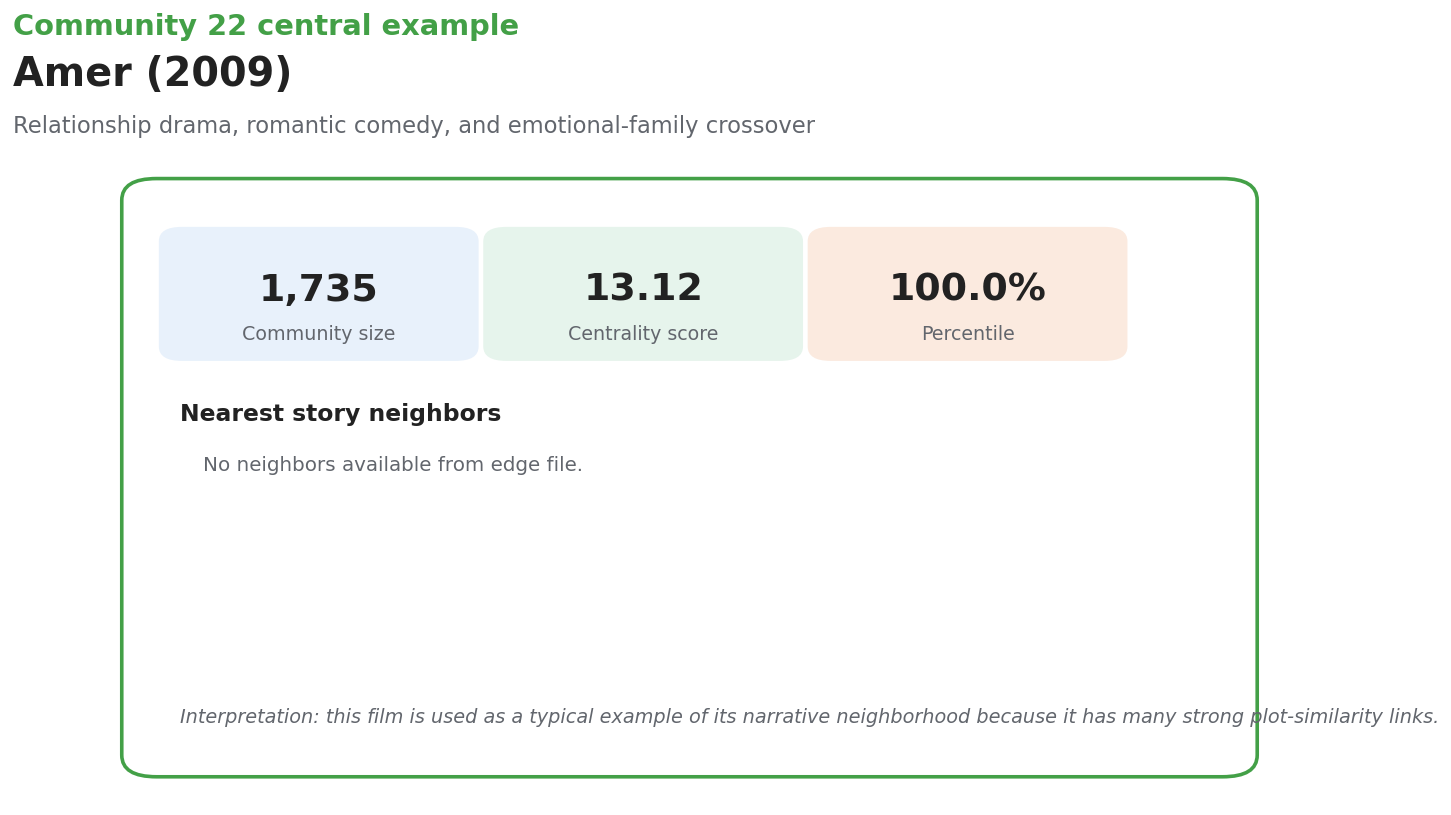

  ✓ 05_central_story_profile_C12.png
  ✓ 05_central_story_profile_C12.svg


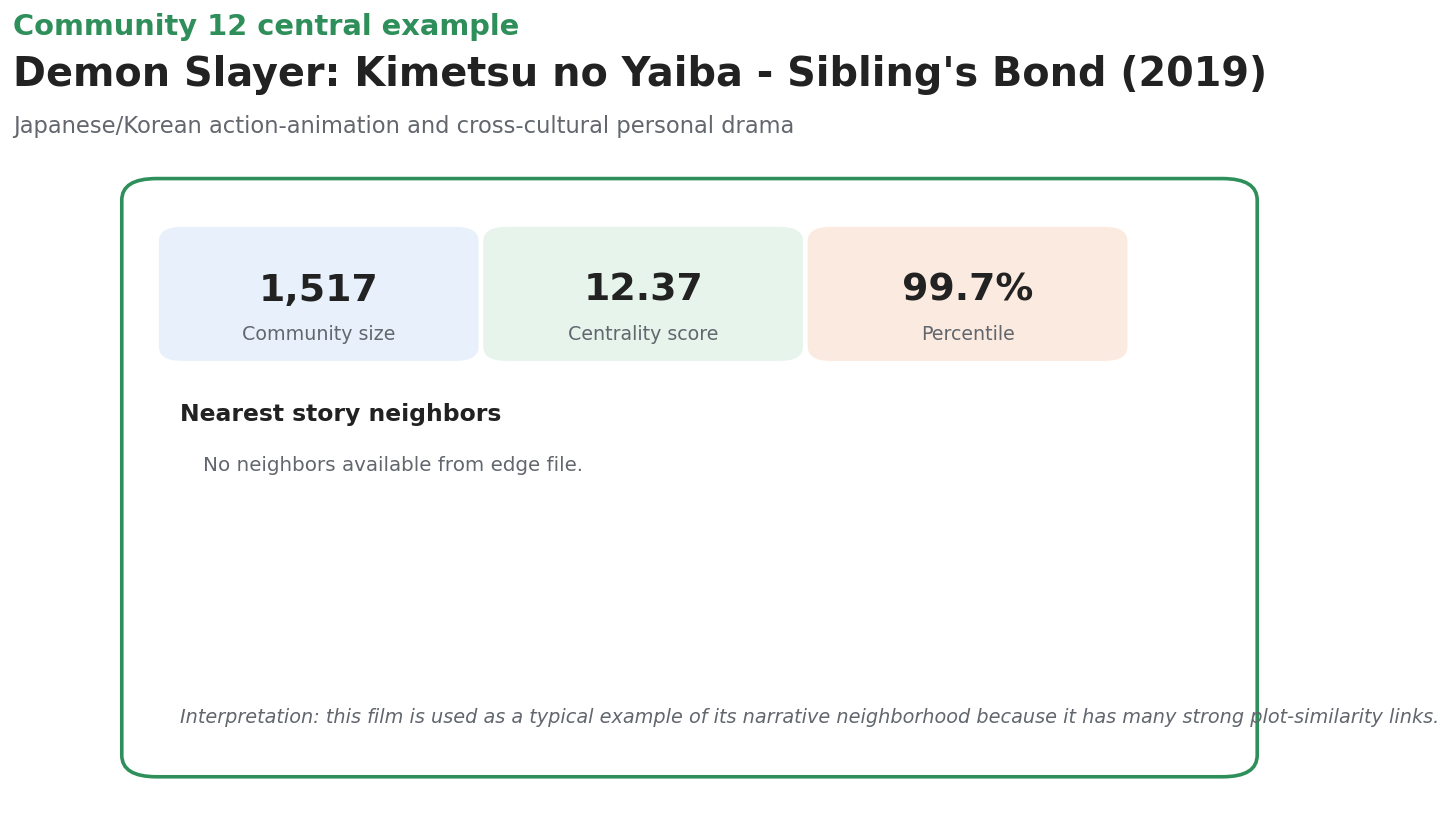

  ✓ 05_central_story_profile_C02.png
  ✓ 05_central_story_profile_C02.svg


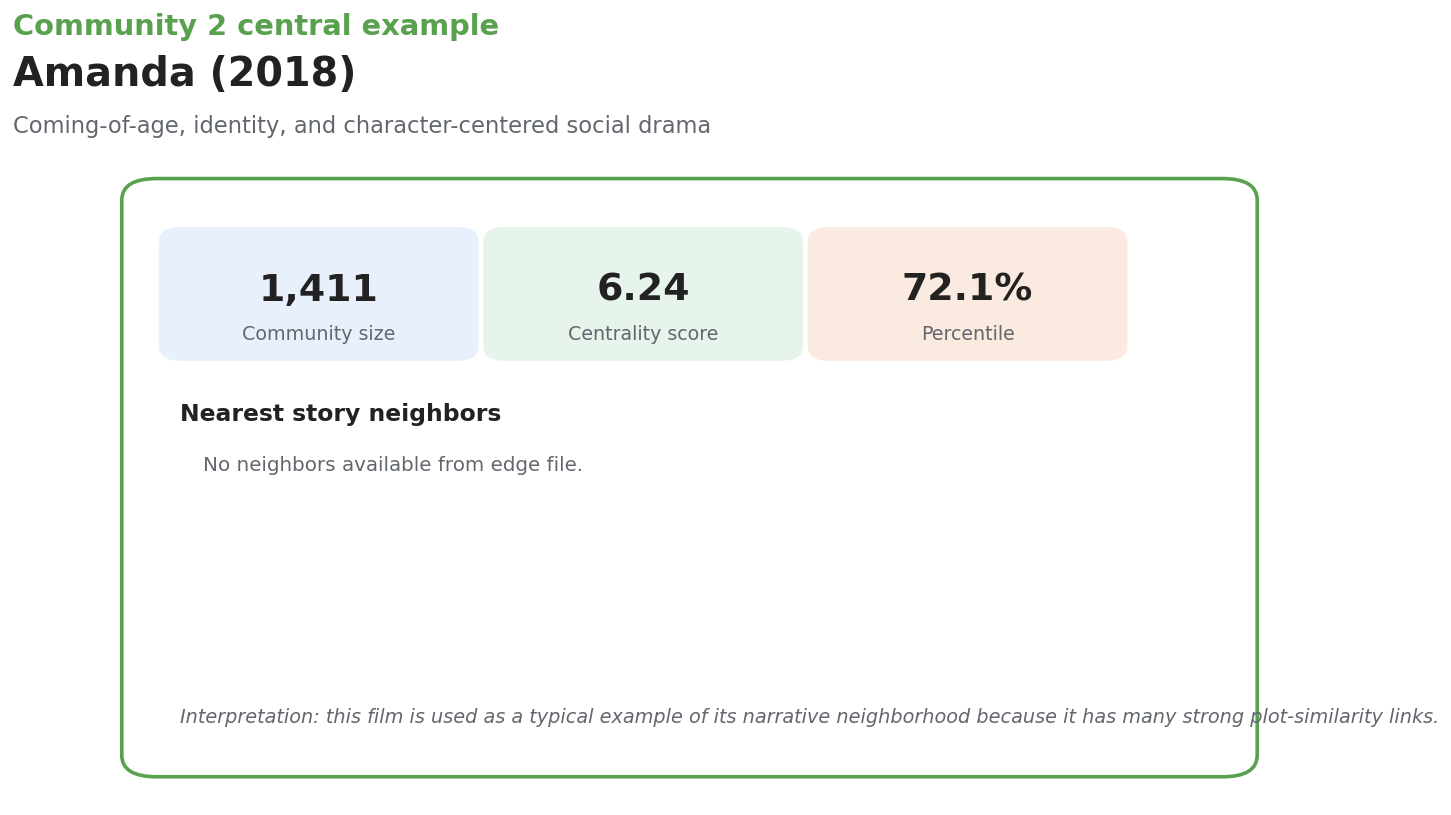

  ✓ 05_central_story_profile_C24.png
  ✓ 05_central_story_profile_C24.svg


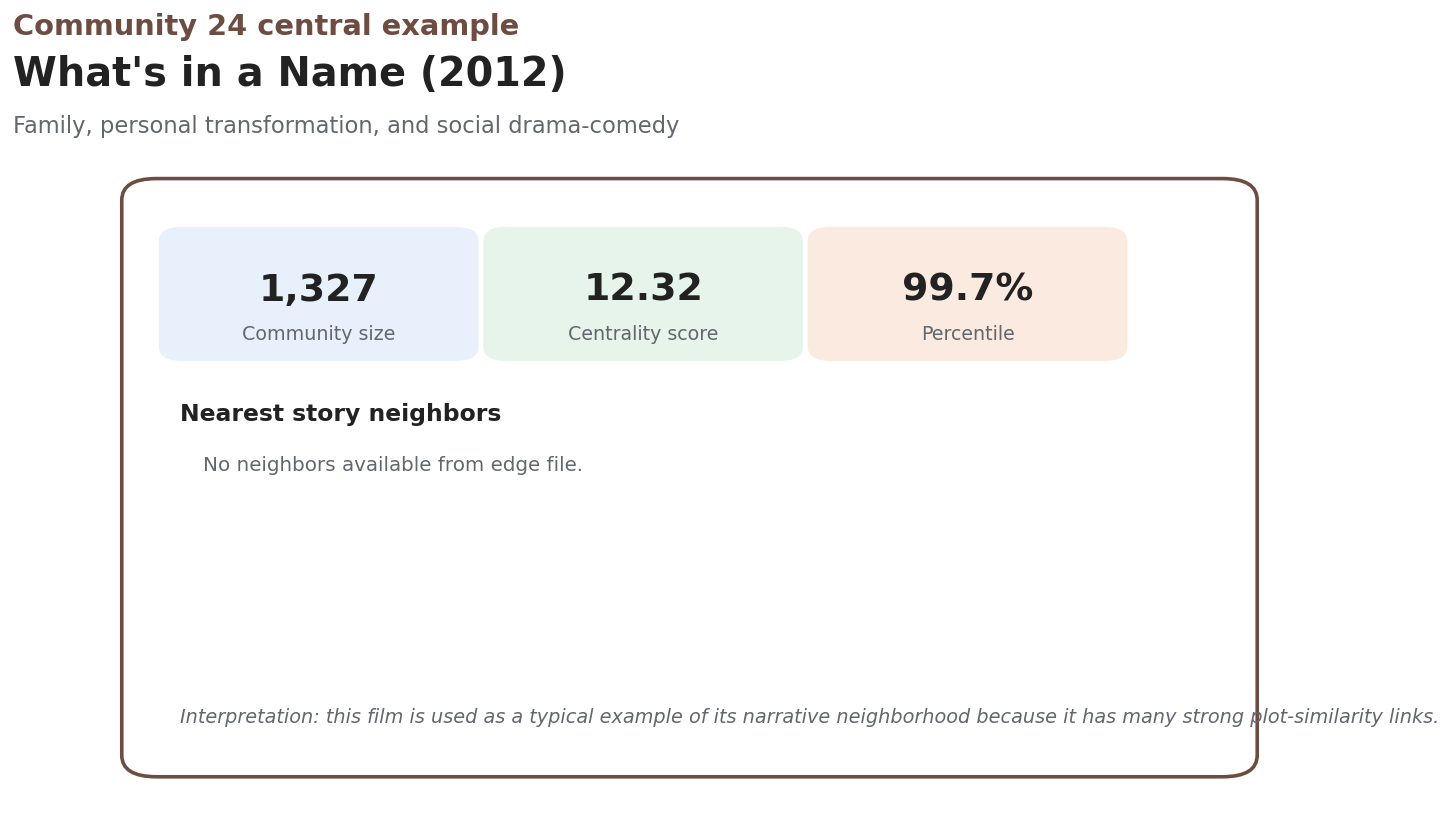

  ✓ 05_central_story_profile_C04.png
  ✓ 05_central_story_profile_C04.svg


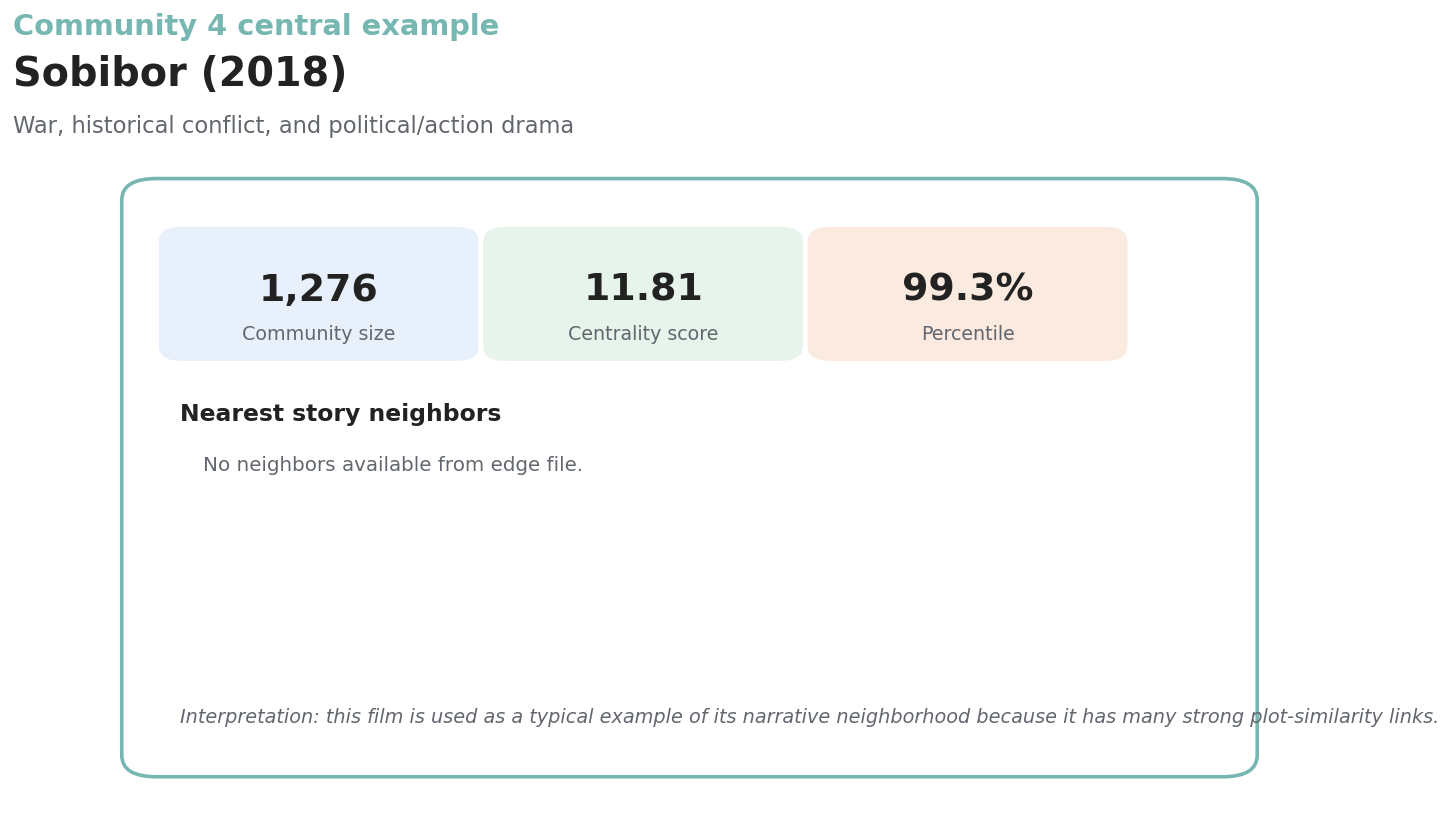

In [37]:

profiles = central_one.sort_values("n_films" if n_films_col else "centrality_score",
                                   ascending=False).head(CFG["profile_communities"]).copy()

for _,r in profiles.iterrows():
    cid     = int(r["community_id"])
    color   = community_color(cid)
    node_id = r[node_id_col]
    title   = clean_title(r.get("title", r.get(title_col, film_title(node_id))))
    year    = r.get(year_col or "release_year", "—")
    try:    year = int(float(year)) if pd.notna(year) else "—"
    except: pass

    neigh   = get_neighbors(node_id, top_n=5)
    label   = str(r.get("narrative_label",""))
    n_films = r.get("n_films", np.nan)
    score   = r.get("centrality_score", np.nan)
    pct     = r.get("centrality_percentile", np.nan)

    fig, ax = plt.subplots(figsize=(11.5, 7.2))
    ax.axis("off")

    fig.text(0.06, 0.93,  f"Community {cid} central example",
             fontsize=16, fontweight="bold", color=color, ha="left")
    fig.text(0.06, 0.875, f"{title} ({year})",
             fontsize=22, fontweight="bold", color=COL["ink"], ha="left")
    fig.text(0.06, 0.825, wrap_text(label, 85),
             fontsize=12.5, color=COL["muted"], ha="left")

    # Stat cards
    pct_txt = f"{float(pct)*100:.1f}%" if pd.notna(pct) else "—"
    for x0, lbl, val, bg in [
        (0.06, "Community size",   fmt_int(n_films),         COL["light_blue"]),
        (0.34, "Centrality score", fmt_float(score, 2),      COL["light_green"]),
        (0.62, "Percentile",       pct_txt,                  COL["light_orange"]),
    ]:
        ax.add_patch(FancyBboxPatch(
            (x0, 0.63), 0.24, 0.15,
            boxstyle="round,pad=0.018,rounding_size=0.02",
            facecolor=bg, edgecolor="none", transform=ax.transAxes))
        ax.text(x0+0.12, 0.71, val,  transform=ax.transAxes,
                ha="center", va="center", fontsize=21, fontweight="bold")
        ax.text(x0+0.12, 0.65, lbl,  transform=ax.transAxes,
                ha="center", va="center", fontsize=10.5, color=COL["muted"])

    # Neighbours
    ax.text(0.06, 0.53, "Nearest story neighbors",
            transform=ax.transAxes, fontsize=13, fontweight="bold")
    y = 0.46
    if len(neigh):
        for i,(_,nr) in enumerate(neigh.head(5).iterrows(), 1):
            sim     = nr.get("edge_weight", np.nan)
            sim_txt = f"{sim:.3f}" if pd.notna(sim) else "n/a"
            ax.text(0.08, y, f"{i}. {shorten(nr['neighbor_title'], 55)} ({nr['neighbor_year']})",
                    transform=ax.transAxes, fontsize=11.0, color=COL["ink"])
            ax.text(0.70, y, f"similarity {sim_txt}",
                    transform=ax.transAxes, fontsize=10.0, color=COL["muted"])
            y -= 0.058
    else:
        ax.text(0.08, y, "No neighbors available from edge file.",
                transform=ax.transAxes, fontsize=11.0, color=COL["muted"])

    ax.text(0.06, 0.11,
        "Interpretation: this film is used as a typical example of its narrative neighborhood "
        "because it has many strong plot-similarity links.",
        transform=ax.transAxes, fontsize=10.7, color=COL["muted"], style="italic")

    ax.add_patch(FancyBboxPatch(
        (0.035,0.06), 0.93, 0.78,
        boxstyle="round,pad=0.025,rounding_size=0.03",
        facecolor="none", edgecolor=color, linewidth=2.0, transform=ax.transAxes))

    save_fig(fig, f"05_central_story_profile_C{cid:02d}.png")
    plt.show()




═══════════════════════════════════════════════════════════════════════════════
15. FIGURE 6 — Local ego-network for selected central films
═══════════════════════════════════════════════════════════════════════════════


In [38]:

selected = profiles.head(3).copy()

for _,r in selected.iterrows():
    cid     = int(r["community_id"])
    color   = community_color(cid)
    node_id = r[node_id_col]
    title   = clean_title(r.get("title", r.get(title_col, film_title(node_id))))
    year    = r.get(year_col or "release_year","—")
    try:    year = int(float(year)) if pd.notna(year) else "—"
    except: pass

    neigh = get_neighbors(node_id, top_n=CFG["neighborhood_films"])
    if len(neigh) == 0:
        print(f"  Skipping C{cid} ({title}) — no neighbours found.")
        continue

    safe_name = re.sub(r"[^A-Za-z0-9]+","_", title)[:25]
    save_table(neigh, f"06_local_neighborhood_C{cid:02d}_{safe_name}.csv")

    fig, ax = plt.subplots(figsize=(11, 8))
    ax.axis("off"); ax.set_xlim(0,1); ax.set_ylim(0,1)
    title_block(fig,
        f"Local story neighborhood: {title}",
        "One central film and its strongest plot-neighbor links.",
        x=0.05, y=0.965)

    center  = (0.50, 0.50)
    ax.scatter(*center, s=2600, color=COL["light_orange"],
               edgecolor=color, linewidth=2.7, zorder=5)
    ax.text(*center, wrap_text(f"{title}\n({year})", 18),
            ha="center", va="center", fontsize=10.5, fontweight="bold", zorder=6)

    n       = min(len(neigh), CFG["neighborhood_films"])
    angles  = np.linspace(0, 2*np.pi, n, endpoint=False)
    radius  = 0.33
    weights = neigh["edge_weight"].fillna(neigh["edge_weight"].median()).values[:n]
    wmin, wmax = np.nanmin(weights), np.nanmax(weights)

    for angle,(_,nr),w in zip(angles, neigh.head(n).iterrows(), weights):
        x = center[0] + radius*np.cos(angle)
        y = center[1] + radius*np.sin(angle)
        ncid   = nr.get("neighbor_community", 0)
        ncolor = community_color(ncid)
        lw     = 1.2 + 4.2*((w-wmin)/(wmax-wmin+1e-9))

        ax.plot([center[0],x],[center[1],y], color=ncolor, alpha=0.62, lw=lw, zorder=1)
        ax.scatter(x, y, s=1200, color=COL["panel"],
                   edgecolor=ncolor, linewidth=1.8, zorder=3)
        ax.text(x, y,
                wrap_text(f"{nr['neighbor_title']}\n({nr['neighbor_year']})", 18),
                ha="center", va="center", fontsize=8.7, fontweight="bold", zorder=4)

    ax.text(0.50, 0.075,
        "Line thickness reflects similarity weight. "
        "This local view is easier to read than a full-network hairball.",
        ha="center", fontsize=10.7, color=COL["muted"], style="italic")

    save_fig(fig, f"06_central_film_local_neighborhood_C{cid:02d}.png")
    plt.show()




  Skipping C14 (The Kindred) — no neighbours found.
  Skipping C22 (Amer) — no neighbours found.
  Skipping C12 (Demon Slayer: Kimetsu no Yaiba - Sibling's Bond) — no neighbours found.


═══════════════════════════════════════════════════════════════════════════════
16. FIGURE 7 — Centrality by community (small multiples, shared y-scale per row)
═══════════════════════════════════════════════════════════════════════════════


  ✓ 07_centrality_by_community_small_multiples.png
  ✓ 07_centrality_by_community_small_multiples.svg


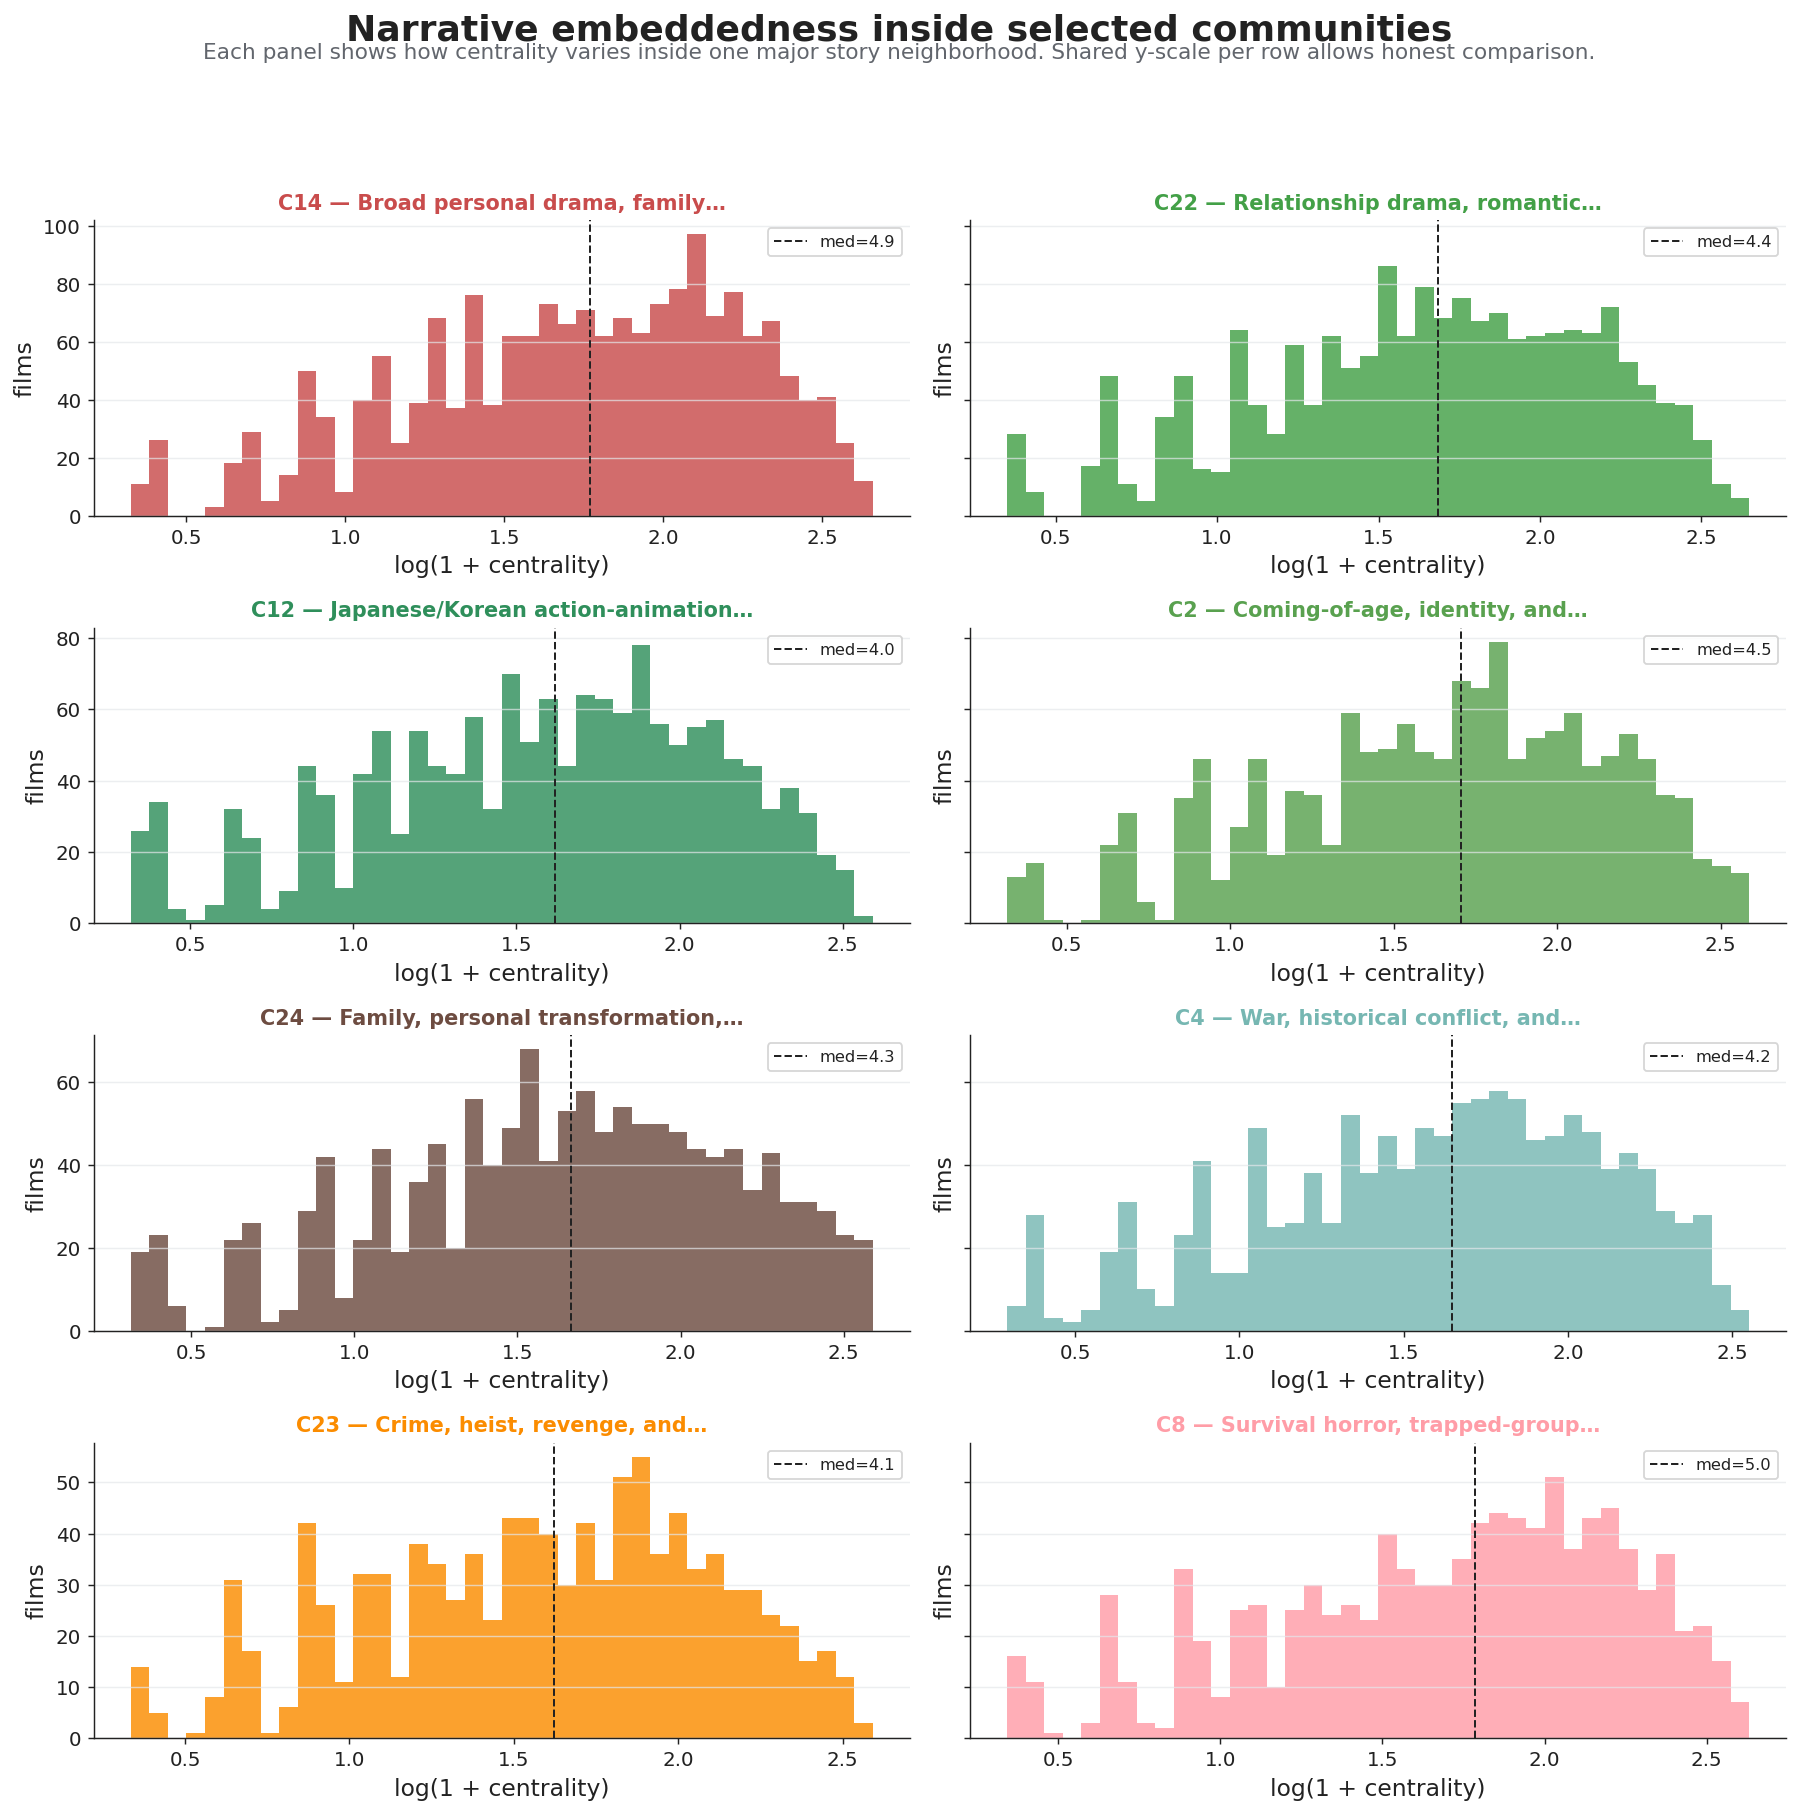

  ✓ 07_centrality_by_community_data.csv


PosixPath('/content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/05_central_story_positions/tables/07_centrality_by_community_data.csv')

In [39]:

top_comms = (central_nodes.groupby("community_id").size()
             .sort_values(ascending=False)
             .head(CFG["top_communities"]).index.tolist())
plot_df   = central_nodes[central_nodes["community_id"].isin(top_comms)].copy()

ncols = 2
nrows = math.ceil(len(top_comms) / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(14, 3.5*nrows),
                         sharey="row")   # ← shared y per row for honest comparison
axes = axes.ravel()

global_max = np.log1p(plot_df["centrality_score"]).max()

for ax,cid in zip(axes, top_comms):
    sub   = plot_df[plot_df["community_id"]==cid]["centrality_score"].dropna()
    color = community_color(cid)

    ax.hist(np.log1p(sub), bins=CFG["hist_bins"], color=color, alpha=0.82)
    ax.axvline(np.log1p(sub.median()), color=COL["ink"], ls="--", lw=1.1,
               label=f"med={sub.median():.1f}")

    lbl = ""
    if community_labels is not None and label_col:
        hit = community_labels[community_labels["community_id"]==cid]
        if len(hit):
            lbl = str(hit.iloc[0][label_col])

    ax.set_title(f"C{int(cid)} — {shorten(lbl, 36)}",
                 fontsize=11.5, fontweight="bold", color=color)
    ax.set_xlabel("log(1 + centrality)")
    ax.set_ylabel("films")
    ax.spines[["top","right"]].set_visible(False)
    ax.grid(axis="y", color=COL["grid"], alpha=0.7)
    ax.legend(fontsize=9, loc="upper right")

for ax in axes[len(top_comms):]:
    ax.axis("off")

fig.suptitle("Narrative embeddedness inside selected communities",
             fontsize=20, fontweight="bold", y=0.995)
fig.text(0.5, 0.97,
    "Each panel shows how centrality varies inside one major story neighborhood. "
    "Shared y-scale per row allows honest comparison.",
    ha="center", fontsize=12, color=COL["muted"])

plt.tight_layout(rect=[0,0,1,0.94])
save_fig(fig, "07_centrality_by_community_small_multiples.png")
plt.show()

save_table(
    plot_df[[node_id_col, title_col, "community_id",
             "centrality_score","centrality_score_norm","centrality_percentile"]],
    "07_centrality_by_community_data.csv"
)




═══════════════════════════════════════════════════════════════════════════════
17. FIGURE 8 — Interpretation summary cards
═══════════════════════════════════════════════════════════════════════════════


  ✓ 08_centrality_interpretation_summary.png
  ✓ 08_centrality_interpretation_summary.svg


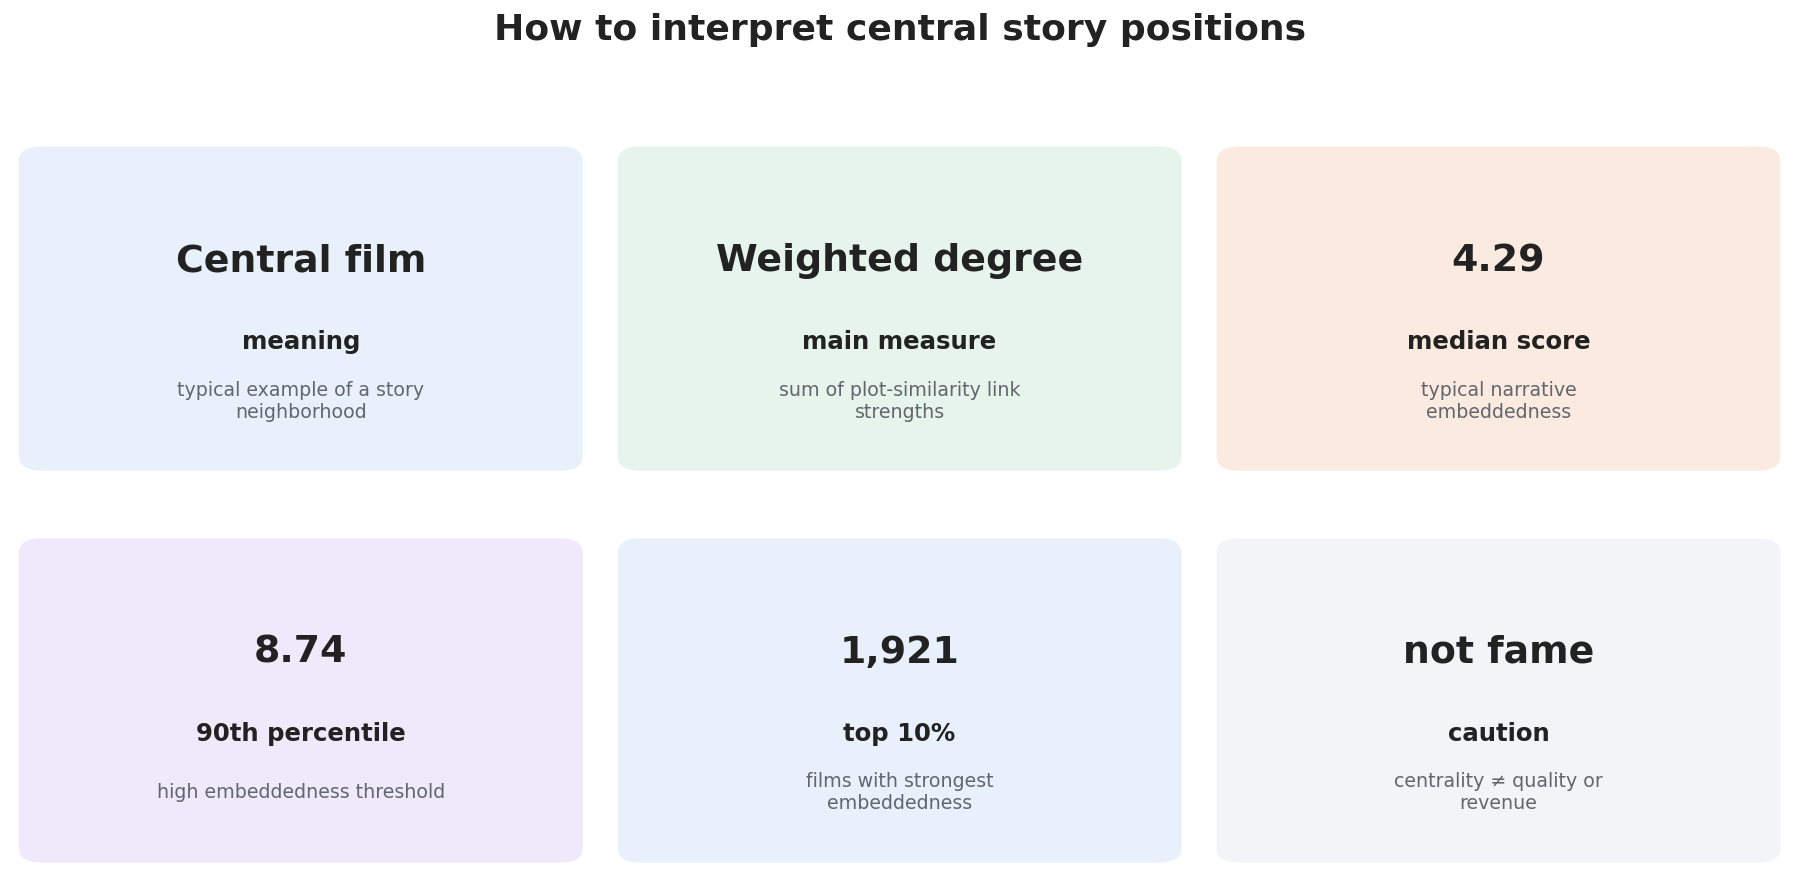

In [40]:

top_pct      = (central_nodes["centrality_percentile"] >= CFG["centrality_high_pct"]).sum()
median_score = central_nodes["centrality_score"].median()
p90_score    = central_nodes["centrality_score"].quantile(CFG["centrality_high_pct"])

cards = [
    ("Central film",         "meaning",           "typical example of a story neighborhood", COL["light_blue"]),
    ("Weighted degree",      "main measure",       "sum of plot-similarity link strengths",   COL["light_green"]),
    (fmt_float(median_score,2), "median score",    "typical narrative embeddedness",          COL["light_orange"]),
    (fmt_float(p90_score,2),    "90th percentile", "high embeddedness threshold",             COL["light_purple"]),
    (fmt_int(top_pct),          "top 10%",         "films with strongest embeddedness",       COL["light_blue"]),
    ("not fame",                "caution",         "centrality ≠ quality or revenue",         COL["light_gray"]),
]

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
axes = axes.ravel()

for ax,(value,title,subtitle,bg) in zip(axes, cards):
    ax.axis("off")
    ax.add_patch(FancyBboxPatch(
        (0.04,0.08), 0.92, 0.82,
        boxstyle="round,pad=0.03,rounding_size=0.04",
        facecolor=bg, edgecolor="none"))
    ax.text(0.5, 0.62, value,    ha="center", va="center", fontsize=21, fontweight="bold")
    ax.text(0.5, 0.40, title,    ha="center", va="center", fontsize=13.5, fontweight="bold")
    ax.text(0.5, 0.24, wrap_text(subtitle,28), ha="center", va="center",
            fontsize=10.5, color=COL["muted"])

fig.suptitle("How to interpret central story positions", fontsize=20, fontweight="bold", y=0.98)
plt.tight_layout(rect=[0,0,1,0.95])
save_fig(fig, "08_centrality_interpretation_summary.png")
plt.show()




═══════════════════════════════════════════════════════════════════════════════
18. INTERPRETATION NOTE
═══════════════════════════════════════════════════════════════════════════════


In [42]:
note = f"""
Brick 5 — Central story positions interpretation note

Main message:
A central film in this thesis is a film strongly embedded in a dense neighborhood
of similar plot descriptions. Centrality is interpreted as story typicality or
narrative embeddedness, not as fame, quality, revenue, or star power.

Centrality measure: weighted degree (sum of all plot-similarity link strengths).
Normalised score range: 0.0 – 1.0 (stored as centrality_score_norm).
Median score:         {median_score:.3f}
90th-percentile score:{p90_score:.3f}
Films in top 10%:     {fmt_int(top_pct)}

Recommended main thesis figures:
  1. 01_centrality_as_story_typicality.png
  2. 02_weighted_degree_explainer.png
  3. 04_central_films_by_community_table.png
  4. Selected 05_central_story_profile_CXX.png
  5. Selected 06_central_film_local_neighborhood_CXX.png

Recommended appendix figures:
  1. 03_weighted_degree_distribution.png
  2. 07_centrality_by_community_small_multiples.png
  3. 08_centrality_interpretation_summary.png

""".strip()

write_text(note, "brick_05_interpretation_note.txt")
print(note)

  ✓ brick_05_interpretation_note.txt
Brick 5 — Central story positions interpretation note

Main message:
A central film in this thesis is a film strongly embedded in a dense neighborhood
of similar plot descriptions. Centrality is interpreted as story typicality or
narrative embeddedness, not as fame, quality, revenue, or star power.

Centrality measure: weighted degree (sum of all plot-similarity link strengths).
Normalised score range: 0.0 – 1.0 (stored as centrality_score_norm).
Median score:         4.295
90th-percentile score:8.736
Films in top 10%:     1,921

Recommended main thesis figures:
  1. 01_centrality_as_story_typicality.png
  2. 02_weighted_degree_explainer.png
  3. 04_central_films_by_community_table.png
  4. Selected 05_central_story_profile_CXX.png
  5. Selected 06_central_film_local_neighborhood_CXX.png

Recommended appendix figures:
  1. 03_weighted_degree_distribution.png
  2. 07_centrality_by_community_small_multiples.png
  3. 08_centrality_interpretation_summar

In [43]:
print("\n" + "="*60)
print("OUTPUT MANIFEST")
print("="*60)

manifest_rows = []
for kind, glob, d in [("figure","*.png",FIG_DIR),("table","*.csv",TABLE_DIR),("text","*.txt",TEXT_DIR)]:
    for p in sorted(d.glob(glob)):
        sz = p.stat().st_size
        manifest_rows.append({"type": kind, "name": p.name,
                               "size_kb": f"{sz/1024:.1f}"})

manifest = pd.DataFrame(manifest_rows)
print(manifest.to_string(index=False))
save_table(manifest, "99_output_manifest.csv")


OUTPUT MANIFEST
  type                                           name size_kb
figure          01_centrality_as_story_typicality.png   374.3
figure               02_weighted_degree_explainer.png   340.1
figure            03_weighted_degree_distribution.png   177.0
figure        04_central_films_by_community_table.png   622.5
figure               05_central_story_profile_C02.png   232.6
figure               05_central_story_profile_C04.png   228.7
figure               05_central_story_profile_C12.png   263.5
figure               05_central_story_profile_C14.png   234.3
figure               05_central_story_profile_C22.png   239.3
figure               05_central_story_profile_C24.png   237.0
figure 07_centrality_by_community_small_multiples.png   473.9
figure       08_centrality_interpretation_summary.png   269.9
 table              00_central_source_for_figures.csv    16.9
 table             00_centrality_node_diagnostics.csv  9201.2
 table    03_weighted_degree_distribution_summary.csv

PosixPath('/content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/05_central_story_positions/tables/99_output_manifest.csv')